# 03 — Framework models, experiments and evaluation (T3, T4, T5a)

Reads saved artefacts only: configurations in `configs/`, checkpoints in `models/`, metrics in `results/`. Produced by `scripts/tune.py` → `scripts/run_final.py` → `scripts/evaluate.py`. Configurations were frozen (`results/freeze_manifest.json`) before the test set was first read.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import data
from src.models import build_model, layer_table, count_params
from src.inference import load_runs

FIG = ROOT / 'results' / 'figures'
M = ROOT / 'results' / 'metrics'
load = lambda p: json.loads(Path(p).read_text())
dcfg = data.load_config(ROOT / 'configs' / 'data_fd001.json')
CAP, W = dcfg['rul_cap'], dcfg['window']
final = {m: load(ROOT / 'configs' / f'final_{m}.json') for m in ('random_forest', 'mlp', 'lstm')}
test = load(M / 'test_metrics.json')
NAMES = {'random_forest': 'Random forest', 'mlp': 'Window MLP', 'lstm': 'LSTM'}

## T3b — Architectures

Both networks receive the same input: a window of the last 30 cycles × 14 scaled sensors, and predict RUL / 125 with a linear output and MSE loss. Layer tables are for a batch of one window.

In [2]:
for m in ('mlp', 'lstm'):
    model = build_model(final[m], W, 14)
    print(f"\n{NAMES[m]}  ({count_params(model):,} trainable parameters)  config: configs/final_{m}.json")
    print(pd.DataFrame(layer_table(model, W, 14), columns=['layer', 'output shape', 'params']).to_string(index=False))


Window MLP  (62,209 trainable parameters)  config: configs/final_mlp.json
  layer output shape  params
  input  (1, 30, 14)       0
Flatten     (1, 420)       0
 Linear     (1, 128)   53888
   ReLU     (1, 128)       0
Dropout     (1, 128)       0
 Linear      (1, 64)    8256
   ReLU      (1, 64)       0
Dropout      (1, 64)       0
 Linear       (1, 1)      65

LSTM  (53,825 trainable parameters)  config: configs/final_lstm.json
                   layer output shape  params
                   input  (1, 30, 14)       0
     LSTM x2 (all steps)  (1, 30, 64)   53760
last time step + Dropout      (1, 64)       0
                  Linear       (1, 1)      65


**Design.** Both networks have two trainable hidden layers and similar capacity (62k vs 54k parameters), so the comparison isolates *how* the window is processed rather than model size.
- **Window MLP**: flattens 30 × 14 into 420 inputs with a separate weight for every cycle-and-sensor position, so it can use order within the fixed window but shares no weights across time and keeps no state. Two ReLU layers (128, 64) with Kaiming initialisation (suited to ReLU), dropout after each.
- **LSTM**: reads the window one cycle at a time; gated recurrent state carries degradation history forward, and the last time step's hidden state (64) feeds a linear head. It uses sigmoid gates and tanh cell activations, not ReLU. Two stacked layers, PyTorch default uniform initialisation, dropout between layers and before the head.
- Shared: linear output and MSE loss. The scaled target is bounded in [0, 1], but the linear output is not, so predictions below 0 are clipped at inference; a bounded output was not tested, Adam (adaptive steps; robust default for both architectures), weight decay 1e-5.

## Fair comparison — pre-registered tuning (`configs/tuning_plan.json`)

In [3]:
tun = load(M / 'tuning.json')
tt = pd.DataFrame(tun['trials'])
tt['overrides'] = tt['overrides'].map(json.dumps)
tt['selected'] = [tun['selected'][m]['trial'] == t for m, t in zip(tt['model'], tt['trial'])]
tt[['model', 'trial', 'overrides', 'val_rmse', 'epochs_completed', 'n_params', 'selected']].round(2)

,model,trial,overrides,val_rmse,epochs_completed,n_params,selected
0,mlp,0,"{""hidden"": [128, 64], ""dropout"": 0.1}",12.80,66.0,62209.0,True
1,mlp,1,"{""hidden"": [128, 64], ""dropout"": 0.3}",13.86,45.0,62209.0,False
2,mlp,2,"{""hidden"": [256, 128], ""dropout"": 0.1}",13.21,28.0,140801.0,False
3,mlp,3,"{""hidden"": [256, 128], ""dropout"": 0.3}",14.70,27.0,140801.0,False
4,lstm,0,"{""hidden"": 32, ""dropout"": 0.1}",13.27,48.0,14625.0,False
5,lstm,1,"{""hidden"": 32, ""dropout"": 0.3}",13.31,69.0,14625.0,False
6,lstm,2,"{""hidden"": 64, ""dropout"": 0.1}",12.94,56.0,53825.0,True
7,lstm,3,"{""hidden"": 64, ""dropout"": 0.3}",13.79,31.0,53825.0,False
8,random_forest,0,"{""max_depth"": 8, ""min_samples_leaf"": 1}",13.58,NaN,NaN,False
9,random_forest,1,"{""max_depth"": 12, ""min_samples_leaf"": 5}",13.00,NaN,NaN,False


All 11 trials are disclosed. For both networks, dropout 0.1 beat 0.3, and the wider MLP (141k parameters) was worse and stopped earlier (27–28 epochs), suggesting extra capacity mostly fitted noise. For the forest, unlimited depth with at least 10 samples per leaf was best. **Limitation:** each candidate was run with seed 0 only, and the top candidates differ by less than the seed-to-seed spread later observed on the test set, so the selection itself is partly noise.

## T3c — Training control and learning curves

Adam, mini-batches of 256, weight decay 1e-5, dropout as selected; early stopping on validation loss with patience 10, restoring the best-epoch weights (saved in `models/<run>.pt`).

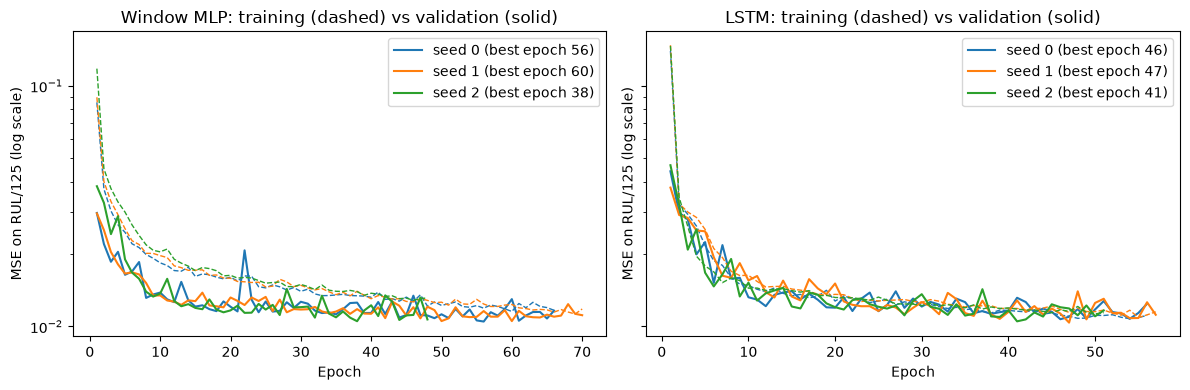

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, m in zip(axes, ('mlp', 'lstm')):
    for s, c in zip((0, 1, 2), ('tab:blue', 'tab:orange', 'tab:green')):
        r = load(M / f'{m}_seed{s}.json')
        ax.plot(range(1, len(r['history']['train_loss']) + 1), r['history']['train_loss'], c=c, ls='--', lw=1)
        ax.plot(range(1, len(r['history']['val_loss']) + 1), r['history']['val_loss'], c=c, label=f'seed {s} (best epoch {r["best_epoch"]})')
    ax.set_yscale('log'); ax.set(title=f'{NAMES[m]}: training (dashed) vs validation (solid)', xlabel='Epoch', ylabel='MSE on RUL/125 (log scale)')
    ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'fig09_learning_curves.png', dpi=150); plt.show()

Both models converge to a validation MSE of about 0.011 (≈ 13 cycles RMSE) by epoch 40, and training and validation curves stay together, so there is little sign of overfitting; early stopping selected epochs 38–60. Early MLP validation loss sits *below* training loss because training loss is averaged over the epoch while weights are still improving, and is computed with dropout active. The isolated spike for MLP seed 0 (epoch 22) is a noisy Adam step that recovers; the checkpoint rule ignores it.

## T4a — Repeated evaluation (seeds 0, 1, 2; fixed split)

Test RMSE uses true RUL capped at 125 (`configs/evaluation_protocol.json`); predictions clipped at 0.

In [5]:
rt = pd.read_csv(ROOT / 'results' / 'results_table.csv')
rt.round(2)

,model,config,seed,checkpoint,val_rmse,test_rmse,test_mae,test_nasa_score,test_rmse_uncapped
0,random_forest,configs/final_random_forest.json,0,models/random_forest_seed0.pkl,12.82,12.25,9.01,232.81,13.55
1,random_forest,configs/final_random_forest.json,1,models/random_forest_seed1.pkl,12.76,11.99,8.90,220.13,13.33
2,random_forest,configs/final_random_forest.json,2,models/random_forest_seed2.pkl,12.77,12.13,9.03,226.20,13.45
3,mlp,configs/final_mlp.json,0,models/mlp_seed0.pt,12.79,13.55,9.97,287.35,15.03
4,mlp,configs/final_mlp.json,1,models/mlp_seed1.pt,12.82,13.74,10.35,295.45,15.13
5,mlp,configs/final_mlp.json,2,models/mlp_seed2.pt,12.82,12.90,9.83,260.64,14.37
6,lstm,configs/final_lstm.json,0,models/lstm_seed0.pt,12.94,13.36,9.91,292.37,14.79
7,lstm,configs/final_lstm.json,1,models/lstm_seed1.pt,12.73,13.64,10.10,288.61,15.30
8,lstm,configs/final_lstm.json,2,models/lstm_seed2.pt,12.81,12.80,9.43,259.57,14.39


In [6]:
summary = pd.DataFrame({NAMES[m]: {
    'val RMSE': f"{test[m]['val_rmse']['mean']:.2f} ± {test[m]['val_rmse']['std']:.2f}",
    'test RMSE': f"{test[m]['test_rmse']['mean']:.2f} ± {test[m]['test_rmse']['std']:.2f}",
    'test MAE': f"{test[m]['test_mae']['mean']:.2f} ± {test[m]['test_mae']['std']:.2f}",
    'test NASA score': f"{test[m]['test_nasa_score']['mean']:.0f} ± {test[m]['test_nasa_score']['std']:.0f}",
    'test RMSE (uncapped truth)': f"{test[m]['test_rmse_uncapped']['mean']:.2f} ± {test[m]['test_rmse_uncapped']['std']:.2f}",
} for m in ('random_forest', 'mlp', 'lstm')}).T
summary

,val RMSE,test RMSE,test MAE,test NASA score,test RMSE (uncapped truth)
Random forest,12.79 ± 0.03,12.13 ± 0.13,8.98 ± 0.07,226 ± 6,13.44 ± 0.11
Window MLP,12.81 ± 0.02,13.40 ± 0.44,10.05 ± 0.27,281 ± 18,14.85 ± 0.41
LSTM,12.83 ± 0.11,13.27 ± 0.43,9.81 ± 0.34,280 ± 18,14.83 ± 0.46


**On validation the three models are indistinguishable (12.79–12.83)**, but on the 100 test engines the random forest is best (12.13 ± 0.13) and both networks are about 1.2 cycles worse, with three times the seed-to-seed spread (± 0.43–0.44). The validation set has only 20 engines, which was not enough to separate the models; this is a genuine finding about the evaluation, not a tuning mistake, and it is why no decision was revisited after the test run. The LSTM's mean test RMSE is 0.13 cycles below the MLP's, far inside the seed spread, so neither network is established as better. RMSE against *uncapped* truth is higher for every model (13.4–14.9) because test engines with true RUL above 125 can never be predicted exactly under the capped target.

## T4b — Prediction quality on the test engines

**Primary metric: RMSE (cycles).** It is in the target's units and penalises large errors, which matter most when scheduling maintenance. **Complementary: MAE** (typical error, less sensitive to outliers) and the **PHM08 score**, which penalises late predictions (over-estimated life) more than early ones.

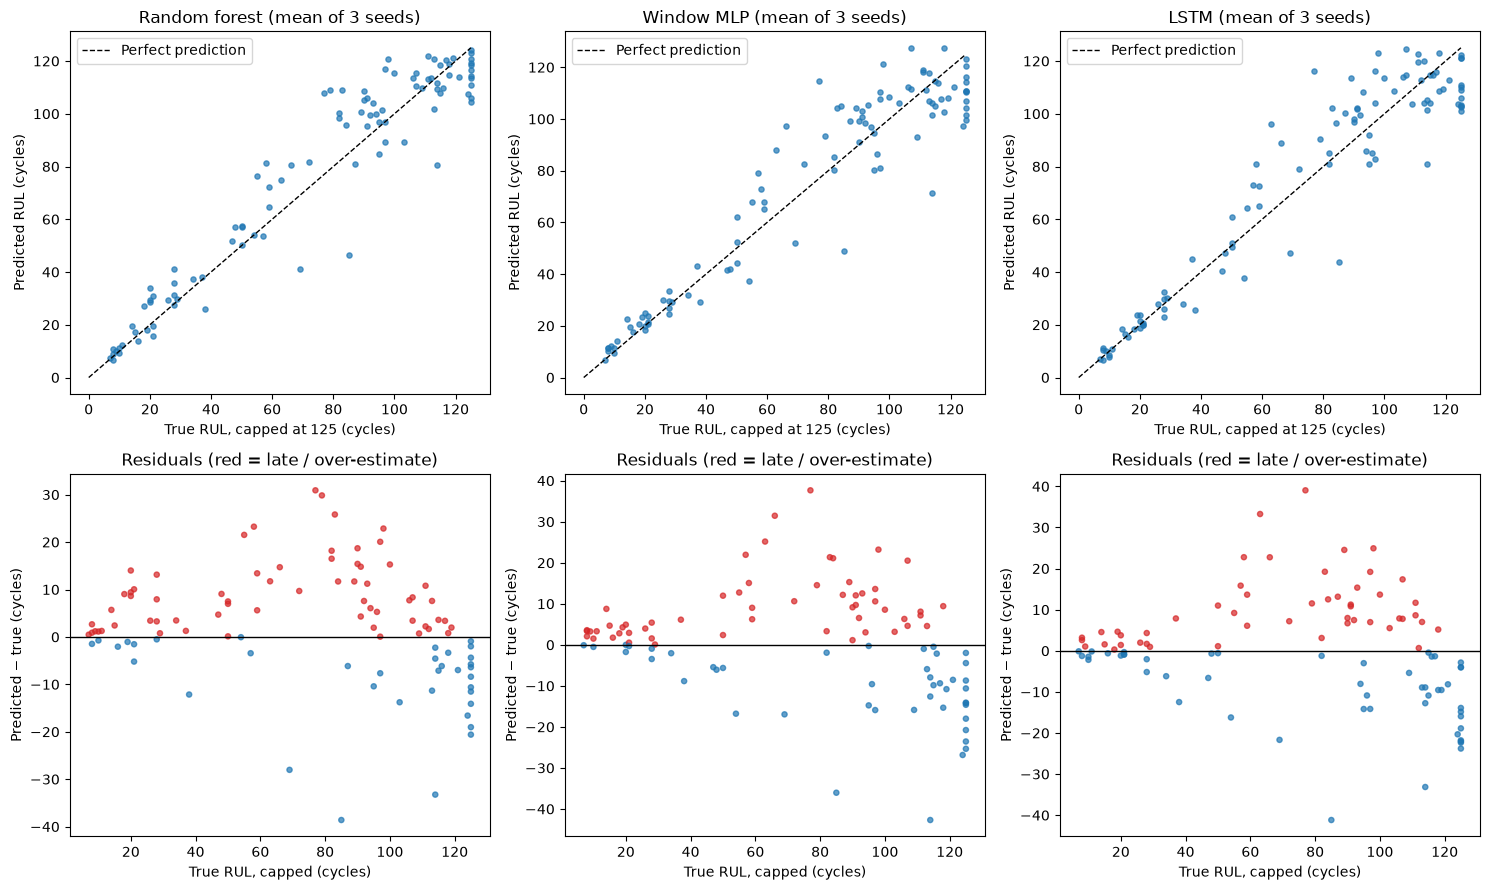

In [7]:
pr = pd.read_csv(ROOT / 'results' / 'test_predictions.csv')
truth = np.minimum(pr['true_rul'], CAP)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, m in enumerate(('random_forest', 'mlp', 'lstm')):
    p = pr[[f'{m}_seed{s}' for s in (0, 1, 2)]].mean(axis=1)
    ax = axes[0, j]; ax.scatter(truth, p, s=14, alpha=0.7)
    ax.plot([0, CAP], [0, CAP], 'k--', lw=1, label='Perfect prediction')
    ax.set(title=f'{NAMES[m]} (mean of 3 seeds)', xlabel='True RUL, capped at 125 (cycles)', ylabel='Predicted RUL (cycles)'); ax.legend()
    ax = axes[1, j]; ax.scatter(truth, p - truth, s=14, alpha=0.7, c=np.where(p - truth > 0, 'tab:red', 'tab:blue'))
    ax.axhline(0, color='k', lw=1)
    ax.set(title='Residuals (red = late / over-estimate)', xlabel='True RUL, capped (cycles)', ylabel='Predicted − true (cycles)')
fig.tight_layout(); fig.savefig(FIG / 'fig10_test_pred_residuals.png', dpi=150); plt.show()

All three models are accurate close to failure (true RUL below ~40 cycles), which is where maintenance decisions matter most. Spread grows with RUL. In the 50–100 cycle range, residuals are mostly **red (late)** for every model: they over-estimate remaining life, the costly direction, which is what the PHM08 score penalises (226 for the forest vs ≈ 280 for both networks). Near the cap, all models under-predict (early, safe errors).

### Predictions in time order on validation engines

For forecasting-style tasks time order matters: each point is the prediction made at that cycle from the preceding 30 cycles.

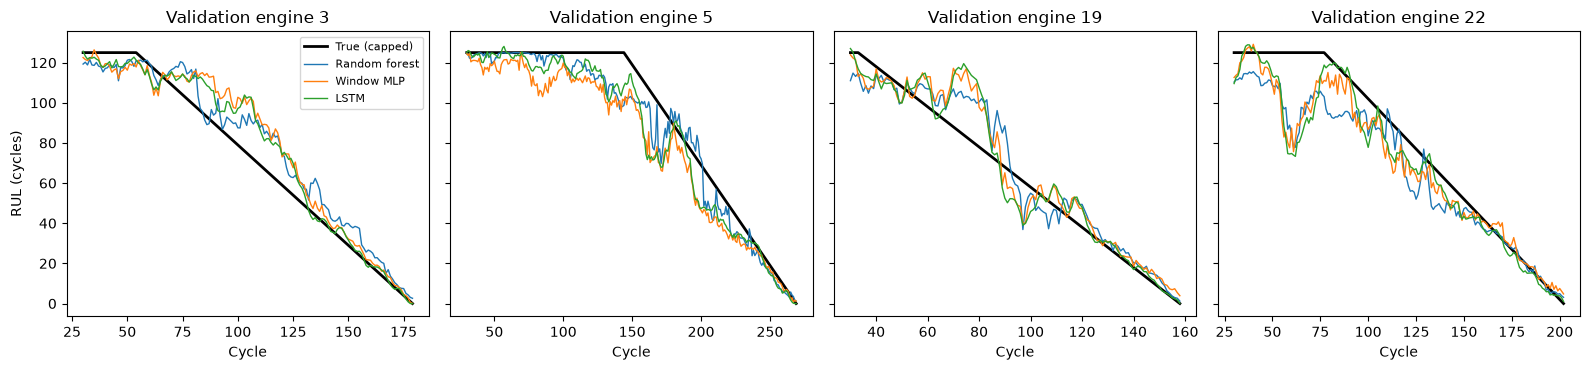

In [8]:
prep = data.load_prepared(dcfg)
X_va, y_va, u_va = prep['val']
models = {m: load_runs(m) for m in ('random_forest', 'mlp', 'lstm')}
pv = {m: np.mean([r.predict(X_va) for r in runs], axis=0) for m, runs in models.items()}
show = sorted(set(u_va))[:4]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, u in zip(axes, show):
    k = u_va == u; cyc = np.arange(W, W + k.sum())
    ax.plot(cyc, y_va[k], 'k', lw=2, label='True (capped)')
    for m in pv: ax.plot(cyc, pv[m][k], lw=1, label=NAMES[m])
    ax.set(title=f'Validation engine {u}', xlabel='Cycle')
axes[0].set_ylabel('RUL (cycles)'); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig11_val_trajectories.png', dpi=150); plt.show()

In time order, all models track the true RUL closely over the final ~50 cycles. Early in life the labelled RUL is flat at 125, but predictions start to fall before the "knee" (engines 5 and 22): the piecewise-linear cap is an assumed labelling, and the sensors show some engines degrading earlier than it says. The short-term ripples come from sensor noise inside the 30-cycle window; the forest's predictions move in steps because tree outputs are piecewise constant.

## T4c — Ablation: does dropout help?

Claim tested: *dropout improves generalisation of the selected architecture.* Single change: dropout → 0.0; all other settings, the split and seeds 0–2 unchanged. Validation data only.

In [9]:
fv = load(M / 'final_validation.json')
arch = fv['ablation_architecture']
ab = pd.DataFrame({'with dropout': fv[arch]['val_rmse'], 'dropout = 0': fv[f'{arch}_nodropout']['val_rmse']}, index=['seed 0', 'seed 1', 'seed 2'])
ab.loc['mean'] = ab.mean(); ab.loc['std'] = ab.iloc[:3].std(ddof=1)
ab['difference'] = ab['dropout = 0'] - ab['with dropout']
print('Architecture:', NAMES[arch], '| dropout in final config:', final[arch]['dropout'])
ab.round(2)

Architecture: Window MLP | dropout in final config: 0.1


,with dropout,dropout = 0,difference
seed 0,12.80,12.72,-0.08
seed 1,12.83,12.68,-0.15
seed 2,12.82,12.62,-0.20
mean,12.81,12.67,-0.14
std,0.01,0.05,0.03


**The claim "dropout improves generalisation" is not supported for the MLP.** Removing dropout *lowered* validation RMSE in all three seeds (by 0.08–0.20, mean 0.14). The effect is consistent but small: it is a third of the test seed spread (0.44). The final configuration was not changed after this result, because the ablation was planned as an explanation, not a further tuning round.
**Remaining confounders:** early stopping and weight decay already regularise the model, so dropout's role overlaps with theirs; dropout 0.1 was itself chosen from only {0.1, 0.3} using seed 0; the 20 validation engines limit precision; the ablation was run on the MLP only.

## T4d — Error analysis

Recommended model, seed-mean predictions. The 5 largest absolute errors and 5 errors near the median.

In [10]:
REC = 'random_forest'
p = pr[[f'{REC}_seed{s}' for s in (0, 1, 2)]].mean(axis=1)
err = pd.DataFrame({'unit': pr['unit'], 'observed cycles': pr['observed_cycles'], 'true RUL': pr['true_rul'],
                    'true (capped)': truth, 'predicted': p.round(1), 'error': (p - truth).round(1)})
err['abs'] = err['error'].abs()
worst = err.nlargest(5, 'abs')
mid = err.iloc[(err['abs'] - err['abs'].median()).abs().argsort()[:5]]
print('Largest errors'); display(worst.drop(columns='abs'))
print('Representative (near-median) errors'); display(mid.drop(columns='abs'))

Largest errors


,unit,observed cycles,true RUL,true (capped),predicted,error
92,93,244,85.0,85.0,46.4,-38.6
44,45,152,114.0,114.0,80.7,-33.3
66,67,71,77.0,77.0,107.9,30.9
49,50,74,79.0,79.0,108.8,29.8
2,3,126,69.0,69.0,41.0,-28.0


Representative (near-median) errors


,unit,observed cycles,true RUL,true (capped),predicted,error
29,30,143,115.0,115.0,107.9,-7.1
16,17,165,50.0,50.0,57.0,7.0
68,69,54,121.0,121.0,114.0,-7.0
71,72,131,50.0,50.0,57.5,7.5
22,23,130,113.0,113.0,120.6,7.6


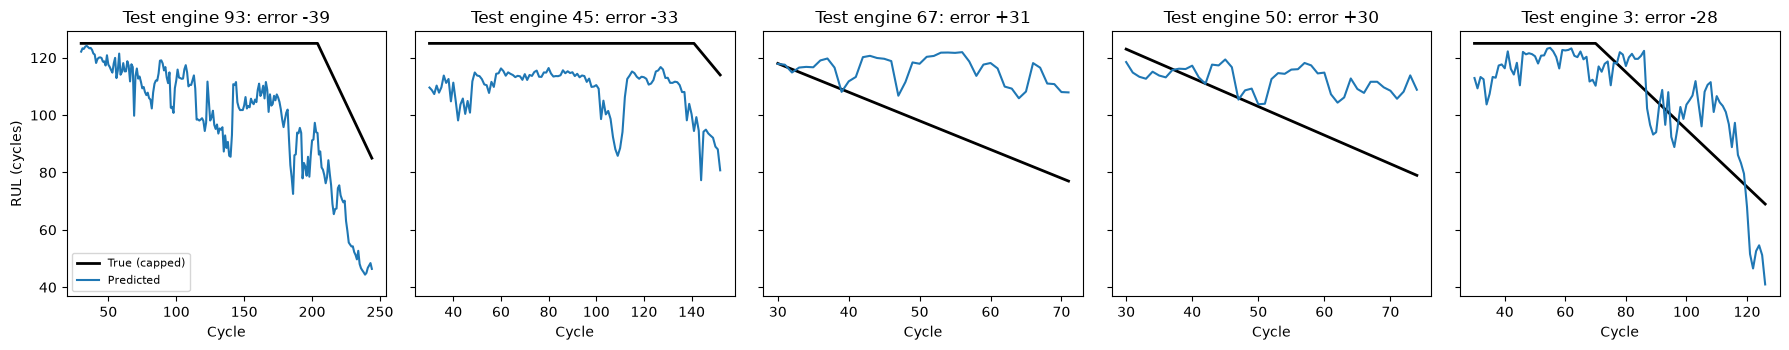

In [11]:
test_raw = data.apply_scaler(data.load_raw('FD001', 'test'), data.load_config(ROOT / dcfg['preprocess_file']))
feats = data.load_config(ROOT / dcfg['preprocess_file'])['features']
runs = models[REC]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for ax, (_, row) in zip(axes, worst.iterrows()):
    g = test_raw[test_raw.unit == row['unit']]
    X = np.stack([g[feats].to_numpy(np.float32)[e - W:e] for e in range(W, len(g) + 1)])
    cyc = g['cycle'].to_numpy()[W - 1:]
    implied = np.minimum(row['true RUL'] + (cyc[-1] - cyc), CAP)
    ax.plot(cyc, implied, 'k', lw=2, label='True (capped)')
    ax.plot(cyc, np.mean([r.predict(X) for r in runs], axis=0), label='Predicted')
    ax.set(title=f"Test engine {int(row['unit'])}: error {row['error']:+.0f}", xlabel='Cycle')
axes[0].set_ylabel('RUL (cycles)'); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig12_worst_engines.png', dpi=150); plt.show()

Representative errors are about ±7 cycles. The five largest errors fall into two clear patterns:
- **Early (under-estimates), engines 93, 45, 3:** long-lived engines whose sensors started drifting well before the label's knee, so the model predicts failure sooner than it happened. Safe, but leads to unnecessary maintenance.
- **Late (over-estimates), engines 67 and 50:** only 71 and 74 cycles observed. The available window still looks healthy, so the model stays at ~110 when the truth is ~78. This is the dangerous failure mode: with short histories there is too little degradation signal.
The trajectories show the same: predictions for engines 67 and 50 stay flat at a "healthy" level throughout.

### Stress tests (protocol fixed in advance in `configs/evaluation_protocol.json`)

Subgroups: short history n=50, long history n=50 (split at median 134 observed cycles)


,short history RMSE,long history RMSE
Random forest,12.73 ± 0.14,11.49 ± 0.12
Window MLP,13.72 ± 0.19,13.07 ± 0.78
LSTM,14.34 ± 0.55,12.09 ± 0.51


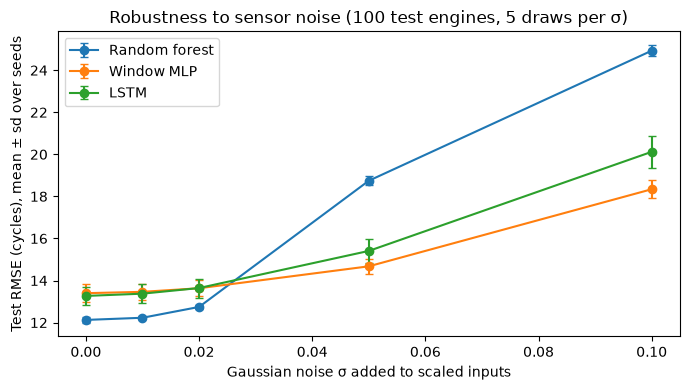

In [12]:
sizes = test['subgroup_sizes']
print(f"Subgroups: short history n={sizes['short_history']}, long history n={sizes['long_history']} "
      f"(split at median {sizes['median_observed_cycles']:.0f} observed cycles)")
sub = pd.DataFrame({NAMES[m]: {'short history RMSE': f"{test[m]['test_rmse_short_history']['mean']:.2f} ± {test[m]['test_rmse_short_history']['std']:.2f}",
                               'long history RMSE': f"{test[m]['test_rmse_long_history']['mean']:.2f} ± {test[m]['test_rmse_long_history']['std']:.2f}"}
                    for m in ('random_forest', 'mlp', 'lstm')}).T
display(sub)

sig = [0.0] + [float(s) for s in test['lstm']['noise_rmse']]
fig, ax = plt.subplots(figsize=(7, 4))
for m in ('random_forest', 'mlp', 'lstm'):
    mean = [test[m]['test_rmse']['mean']] + [v['mean'] for v in test[m]['noise_rmse'].values()]
    sd = [test[m]['test_rmse']['std']] + [v['std'] for v in test[m]['noise_rmse'].values()]
    ax.errorbar(sig, mean, yerr=sd, marker='o', capsize=3, label=NAMES[m])
ax.set(xlabel='Gaussian noise σ added to scaled inputs', ylabel='Test RMSE (cycles), mean ± sd over seeds',
       title='Robustness to sensor noise (100 test engines, 5 draws per σ)')
ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'fig13_noise_stress.png', dpi=150); plt.show()

**Subgroup (n = 50 per group).** Every model is worse on engines with short histories, and the LSTM is the most sensitive (14.34 vs 12.09). With 50 engines per group and no confidence intervals, this shows a consistent direction, not a statistically established gap.
**Sensor noise.** The forest is best on clean or lightly noisy data (σ ≤ 0.02), but degrades sharply: 18.7 cycles at σ = 0.05 and 24.9 at σ = 0.10, against 14.7 / 18.3 for the MLP and 15.4 / 20.1 for the LSTM. Its splits depend on window features such as the last value and the standard deviation, which noise corrupts directly, whereas the networks learn weighted combinations across all 30 cycles. **What this cannot establish:** real sensor faults are not independent Gaussian noise (drift, dropouts and bias are more likely), and σ is relative to the min-max-scaled training range.

## T5a — Model recommendation

Inference time: one CPU process, median of 50 calls (`configs/evaluation_protocol.json`).

In [13]:
import platform, torch
print('Hardware:', platform.processor() or platform.machine(), '| torch threads:', torch.get_num_threads())
rec = pd.DataFrame({NAMES[m]: {
    'test RMSE': f"{test[m]['test_rmse']['mean']:.2f} ± {test[m]['test_rmse']['std']:.2f}",
    'NASA score': f"{test[m]['test_nasa_score']['mean']:.0f}",
    'size': f"{test[m]['n_params']:,} params" if test[m]['n_params'] else f"{test[m]['rf_total_nodes']:,} tree nodes",
    'ms / 1 engine': round(test[m]['inference_ms']['batch_1'], 2), 'ms / 100 engines': round(test[m]['inference_ms']['batch_100'], 2)}
    for m in ('random_forest', 'mlp', 'lstm')}).T
rec

Hardware: x86_64 | torch threads: 8


,test RMSE,NASA score,size,ms / 1 engine,ms / 100 engines
Random forest,12.13 ± 0.13,226,"373,148 tree nodes",55.7,75.11
Window MLP,13.40 ± 0.44,281,"62,209 params",0.21,1.99
LSTM,13.27 ± 0.43,280,"53,825 params",0.62,3.33


**Recommendation: the random forest for FD001-like data, with the window MLP as the preferred neural model and the better choice if inputs are noisier than the benchmark.**
- *Quality and stability:* the forest has the lowest test RMSE, the lowest seed variability and the best PHM08 score, so on this benchmark the simpler, non-neural model is preferable.
- *Cost:* 56 ms per engine at batch size 1 on CPU is ample for decisions made once per flight cycle, although the forest is far larger (373k tree nodes) and slower than the MLP (0.21 ms, 62k parameters). The forest timing includes thread start-up from `n_jobs=-1`, so it overstates intrinsic cost.
- *Robustness:* if sensor noise above ~2 % of the training range is plausible, the MLP's advantage under noise outweighs its 1.3-cycle clean-data penalty.
- *LSTM:* its mean test RMSE is 0.13 cycles lower than the MLP's, but within seed variation, and it is less robust to noise at three times the inference time, so its advantage is not established and it is not recommended on this evidence.
The hypothesis that recurrent modelling beats a fixed-window MLP is **not confirmed on FD001**; note that the window MLP also sees temporal order inside its window. None of these results justify deployment: one simulated benchmark subset, one fault mode, 100 test engines.